<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Scatter Plot**


Estimated time needed: **45** minutes


## Overview

In this lab, you will focus on creating and interpreting scatter plots to visualize relationships between variables and trends in the dataset. The provided dataset will be directly loaded into a pandas DataFrame, and various scatter plot-related visualizations will be created to explore developer trends, compensation, and preferences.



## Objectives


In this lab, you will:

- Create and analyze scatter plots to examine relationships between variables.

- Use scatter plots to identify trends and patterns in the dataset.

- Focus on visualizations centered on scatter plots for better data-driven insights.


## Setup: Working with the Database



**Install and import the required libraries**


In [1]:
!pip install pandas
!pip install matplotlib

import pandas as pd
import matplotlib.pyplot as plt

#### Step 1: Load the dataset


In [2]:
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

df = pd.read_csv(file_path)



### Task 1: Exploring Relationships with Scatter Plots



#### 1. Scatter Plot for Age vs. Job Satisfaction



Visualize the relationship between respondents' age (`Age`) and job satisfaction (`JobSatPoints_6`). Use this plot to identify any patterns or trends.




Rows plotted: 29399
Correlation: -0.05

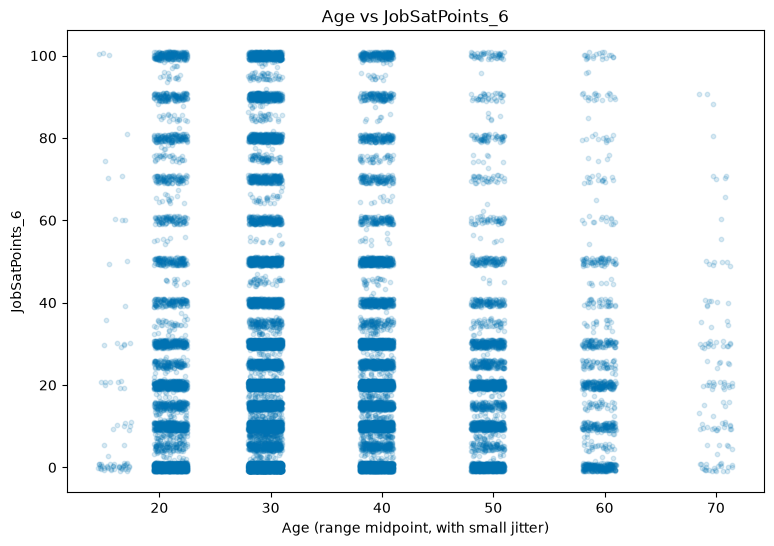

In [3]:
## Write your code here
import numpy as np

age_map = {
    "Under 18 years old": 16,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 70,
}

d = df[["Age", "JobSatPoints_6"]].copy()
d["Age_numeric"] = d["Age"].map(age_map)
d["JobSatPoints_6"] = pd.to_numeric(d["JobSatPoints_6"], errors="coerce")
d = d.dropna(subset=["Age_numeric", "JobSatPoints_6"])
print("Rows plotted:", len(d))
print("Correlation:", round(d["Age_numeric"].corr(d["JobSatPoints_6"]), 3))

rng = np.random.default_rng(0)
plt.figure(figsize=(9, 6))
plt.scatter(d["Age_numeric"] + rng.uniform(-1.5, 1.5, len(d)),
            d["JobSatPoints_6"] + rng.uniform(-1, 1, len(d)),
            alpha=0.15, s=10, color="#0072B2")
plt.title("Age vs JobSatPoints_6")
plt.xlabel("Age (range midpoint, with small jitter)")
plt.ylabel("JobSatPoints_6")
plt.show()

#### 2. Scatter Plot for Compensation vs. Job Satisfaction


Explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) using a scatter plot.


Rows with both values: 16185
95th percentile cap: 205000.0
Correlation (capped data): -0.087

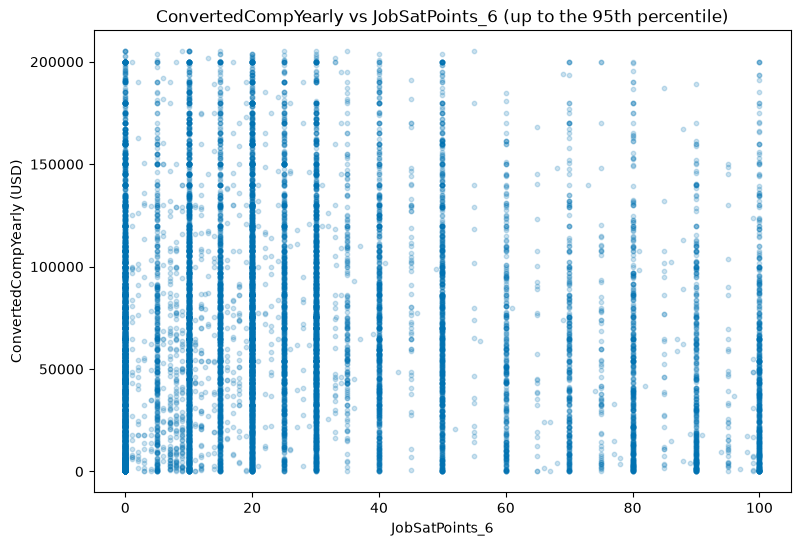

In [4]:
## Write your code here
## Write your code here
d2 = df[["ConvertedCompYearly", "JobSatPoints_6"]].copy()
d2["JobSatPoints_6"] = pd.to_numeric(d2["JobSatPoints_6"], errors="coerce")
d2 = d2.dropna()
print("Rows with both values:", len(d2))

cap = d2["ConvertedCompYearly"].quantile(0.95)
print("95th percentile cap:", cap)
d2 = d2[d2["ConvertedCompYearly"] <= cap]
print("Correlation (capped data):", round(d2["ConvertedCompYearly"].corr(d2["JobSatPoints_6"]), 3))

plt.figure(figsize=(9, 6))
plt.scatter(d2["JobSatPoints_6"], d2["ConvertedCompYearly"], alpha=0.2, s=10, color="#0072B2")
plt.title("ConvertedCompYearly vs JobSatPoints_6 (up to the 95th percentile)")
plt.xlabel("JobSatPoints_6")
plt.ylabel("ConvertedCompYearly (USD)")
plt.show()

### Task 2: Enhancing Scatter Plots


#### 1. Scatter Plot with Trend Line for Age vs. Job Satisfaction



Add a regression line to the scatter plot of Age vs. JobSatPoints_6 to highlight trends in the data.


Slope: -0.14 | Intercept: 29.15

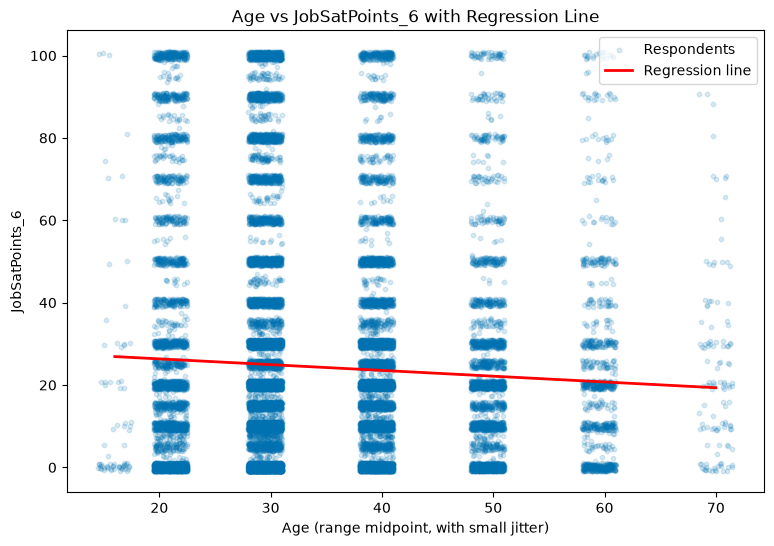

In [5]:

## Write your code here
d = df[["Age", "JobSatPoints_6"]].copy()
d["Age_numeric"] = d["Age"].map(age_map)
d["JobSatPoints_6"] = pd.to_numeric(d["JobSatPoints_6"], errors="coerce")
d = d.dropna(subset=["Age_numeric", "JobSatPoints_6"])

slope, intercept = np.polyfit(d["Age_numeric"], d["JobSatPoints_6"], 1)
print("Slope:", round(slope, 3), "| Intercept:", round(intercept, 2))

rng = np.random.default_rng(0)
plt.figure(figsize=(9, 6))
plt.scatter(d["Age_numeric"] + rng.uniform(-1.5, 1.5, len(d)),
            d["JobSatPoints_6"] + rng.uniform(-1, 1, len(d)),
            alpha=0.15, s=10, color="#0072B2", label="Respondents")
x_line = np.array([d["Age_numeric"].min(), d["Age_numeric"].max()])
plt.plot(x_line, slope * x_line + intercept, color="red", linewidth=2, label="Regression line")
plt.title("Age vs JobSatPoints_6 with Regression Line")
plt.xlabel("Age (range midpoint, with small jitter)")
plt.ylabel("JobSatPoints_6")
plt.legend()
plt.show()

#### 2. Scatter Plot for Age vs. Work Experience


Visualize the relationship between Age (`Age`) and Work Experience (`YearsCodePro`) using a scatter plot.


Rows plotted: 51487
Correlation: 0.834

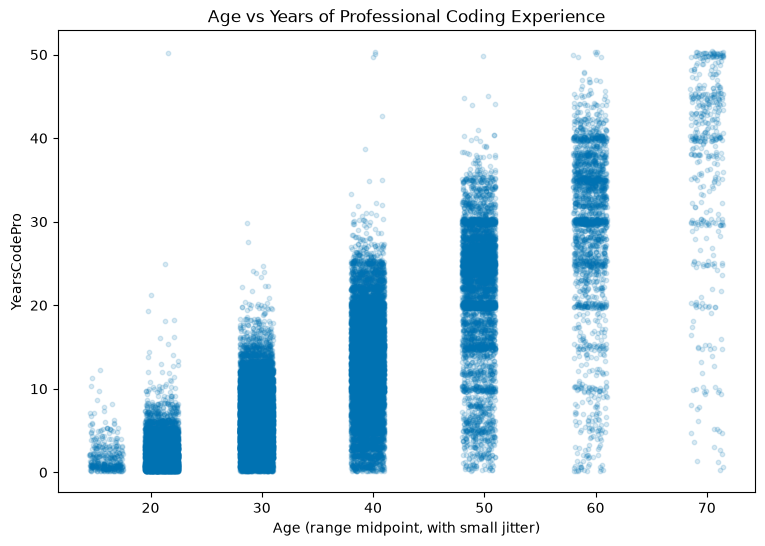

In [6]:

## Write your code here
d3 = df[["Age", "YearsCodePro"]].copy()
d3["Age_numeric"] = d3["Age"].map(age_map)
d3["Years"] = pd.to_numeric(
    d3["YearsCodePro"].replace({"Less than 1 year": 0.5, "More than 50 years": 50}), errors="coerce")
d3 = d3.dropna(subset=["Age_numeric", "Years"])
print("Rows plotted:", len(d3))
print("Correlation:", round(d3["Age_numeric"].corr(d3["Years"]), 3))

rng = np.random.default_rng(0)
plt.figure(figsize=(9, 6))
plt.scatter(d3["Age_numeric"] + rng.uniform(-1.5, 1.5, len(d3)),
            d3["Years"] + rng.uniform(-0.4, 0.4, len(d3)),
            alpha=0.15, s=10, color="#0072B2")
plt.title("Age vs Years of Professional Coding Experience")
plt.xlabel("Age (range midpoint, with small jitter)")
plt.ylabel("YearsCodePro")
plt.show()

### Task 3: Combining Scatter Plots with Additional Features


#### 1. Bubble Plot of Compensation vs. Job Satisfaction with Age as Bubble Size



Create a bubble plot to explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), with bubble size representing age.


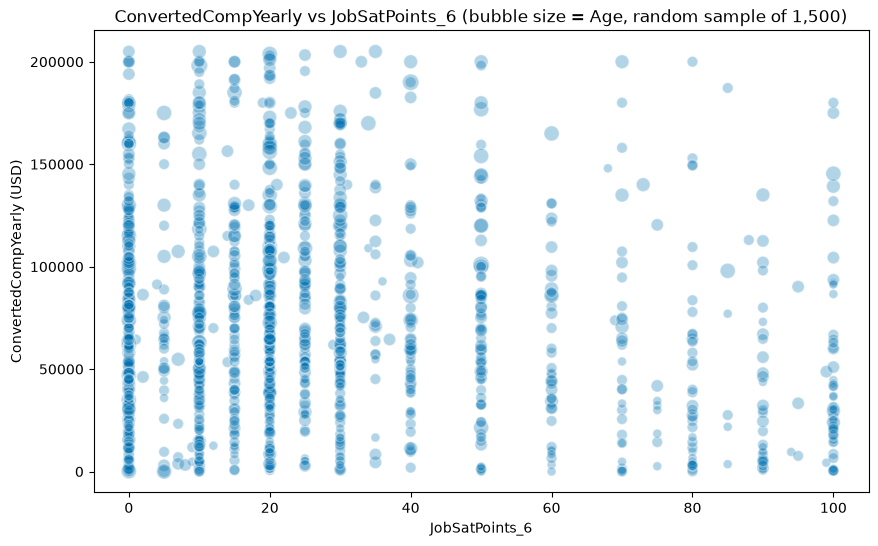

In [7]:
## Write your code here
d = df[["ConvertedCompYearly", "JobSatPoints_6", "Age"]].copy()
d["JobSatPoints_6"] = pd.to_numeric(d["JobSatPoints_6"], errors="coerce")
d["Age_numeric"] = d["Age"].map(age_map)
d = d.dropna(subset=["ConvertedCompYearly", "JobSatPoints_6", "Age_numeric"])
d = d[d["ConvertedCompYearly"] <= d["ConvertedCompYearly"].quantile(0.95)]

sample = d.sample(1500, random_state=1)
plt.figure(figsize=(10, 6))
plt.scatter(sample["JobSatPoints_6"], sample["ConvertedCompYearly"],
            s=sample["Age_numeric"] * 2, alpha=0.3, color="#0072B2", edgecolor="white")
plt.title("ConvertedCompYearly vs JobSatPoints_6 (bubble size = Age, random sample of 1,500)")
plt.xlabel("JobSatPoints_6")
plt.ylabel("ConvertedCompYearly (USD)")
plt.show()

#### 2. Scatter Plot for Popular Programming Languages by Job Satisfaction


Visualize the popularity of programming languages (`LanguageHaveWorkedWith`) against job satisfaction using a scatter plot. Use points to represent satisfaction levels for each language.


                         respondents  avg_jobsat
Language                                        
JavaScript                     18480        6.96
SQL                            16104        6.94
HTML/CSS                       15371        6.94
Python                         14289        6.90
TypeScript                     12559        7.02
Bash/Shell (all shells)        10687        6.93
Java                            8734        6.92
C#                              8571        6.98
C++                             5809        6.94
PHP                             5288        6.95
C                               4876        6.95
PowerShell                      4466        6.92
Go                              4350        6.99
Rust                            3514        6.91
Kotlin                          2914        7.08

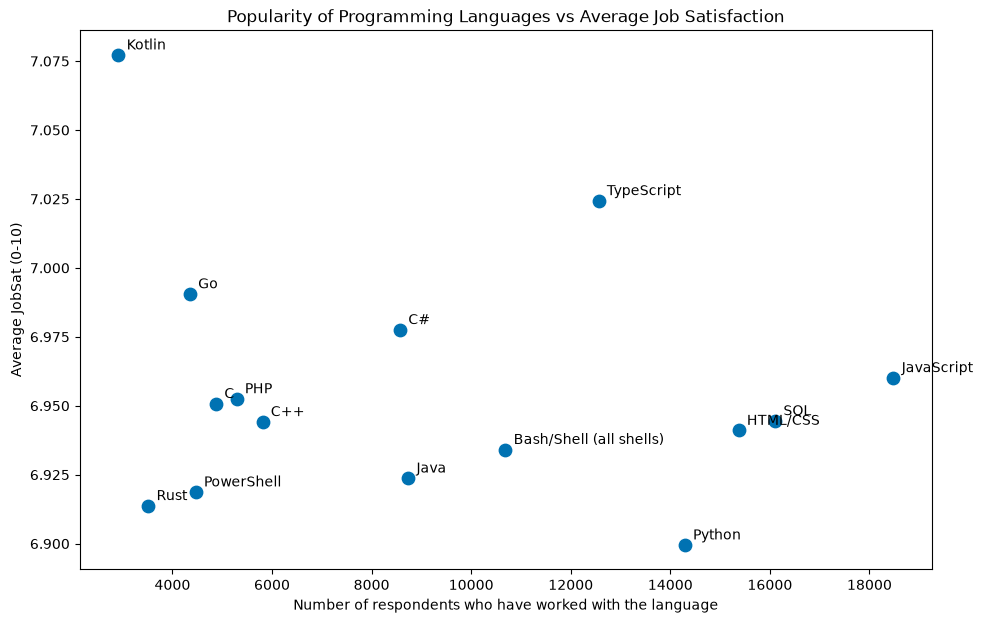

In [8]:
## Write your code here
d = df[["LanguageHaveWorkedWith", "JobSat"]].copy()
d["JobSat"] = pd.to_numeric(d["JobSat"], errors="coerce")
d = d.dropna(subset=["LanguageHaveWorkedWith", "JobSat"])
d["Language"] = d["LanguageHaveWorkedWith"].str.split(";")
d = d.explode("Language")
d["Language"] = d["Language"].str.strip()

lang = d.groupby("Language").agg(respondents=("JobSat", "size"), avg_jobsat=("JobSat", "mean"))
top = lang.sort_values("respondents", ascending=False).head(15)
print(top.round(2))

plt.figure(figsize=(11, 7))
plt.scatter(top["respondents"], top["avg_jobsat"], s=80, color="#0072B2")
for name, row in top.iterrows():
    plt.annotate(name, (row["respondents"], row["avg_jobsat"]), textcoords="offset points", xytext=(6, 4))
plt.title("Popularity of Programming Languages vs Average Job Satisfaction")
plt.xlabel("Number of respondents who have worked with the language")
plt.ylabel("Average JobSat (0-10)")
plt.show()

### Task 4: Scatter Plot Comparisons Across Groups


#### 1. Scatter Plot for Compensation vs. Job Satisfaction by Employment Type


Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), categorized by employment type (`Employment`). Use color coding or markers to differentiate between employment types.


Employment
Employed, full-time                                     11997
Independent contractor, freelancer, or self-employed      597
Employed, part-time                                       288
Name: count, dtype: int64

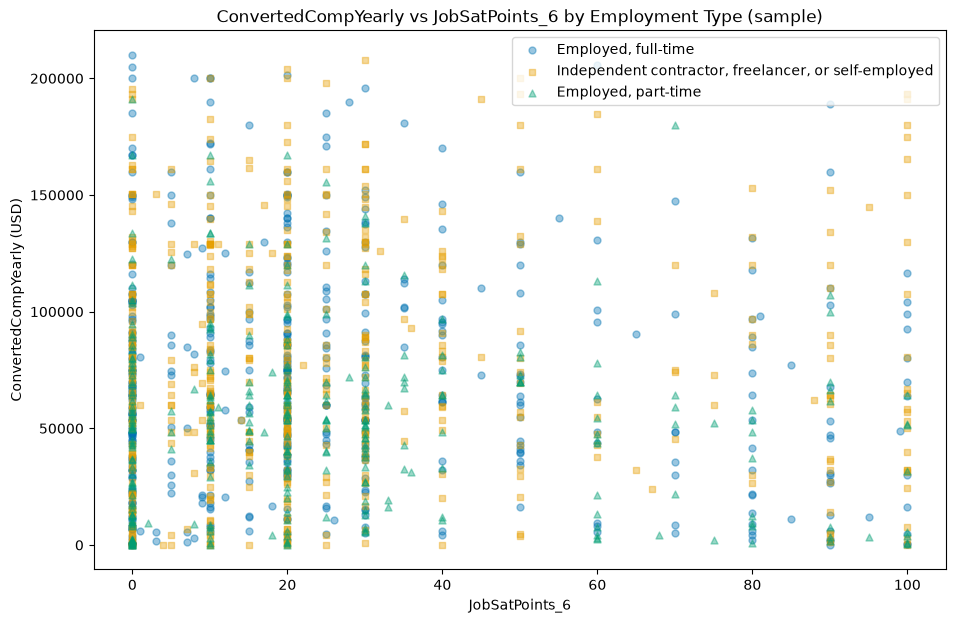

In [11]:
## Write your code here
d = df[["Employment", "ConvertedCompYearly", "JobSatPoints_6"]].copy()
d["JobSatPoints_6"] = pd.to_numeric(d["JobSatPoints_6"], errors="coerce")
d = d.dropna()
d = d[~d["Employment"].str.contains(";")]          # keep respondents with a single employment type
d = d[d["ConvertedCompYearly"] <= d["ConvertedCompYearly"].quantile(0.95)]

top_emp = d["Employment"].value_counts().head(3).index.tolist()
print(d["Employment"].value_counts().head(3))

colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
markers = ["o", "s", "^", "D"]
plt.figure(figsize=(11, 7))
for emp, c, m in zip(top_emp, colors, markers):
    g = d[d["Employment"] == emp]
    g = g.sample(min(len(g), 500), random_state=1)
    plt.scatter(g["JobSatPoints_6"], g["ConvertedCompYearly"], alpha=0.4, s=25, color=c, marker=m, label=emp)
plt.title("ConvertedCompYearly vs JobSatPoints_6 by Employment Type (sample)")
plt.xlabel("JobSatPoints_6")
plt.ylabel("ConvertedCompYearly (USD)")
plt.legend()
plt.show()

#### 2. Scatter Plot for Work Experience vs. Age Group by Country


Compare work experience (`YearsCodePro`) across different age groups (`Age`) and countries (`Country`). Use colors to represent different countries and markers for age groups.


                                             Country                Age  avg_years    n  age_mid
                                             Germany Under 18 years old        1.7   26     16.0
                                             Germany    18-24 years old        2.6  702     21.0
                                             Germany    25-34 years old        6.1 1763     29.5
                                             Germany    35-44 years old       13.1 1162     39.5
                                             Germany    45-54 years old       21.9  437     49.5
                                             Germany    55-64 years old       29.5  204     59.5
                                               India Under 18 years old        2.6   35     16.0
                                               India    18-24 years old        1.7 1153     21.0
                                               India    25-34 years old        5.9 1608     29.5
                              

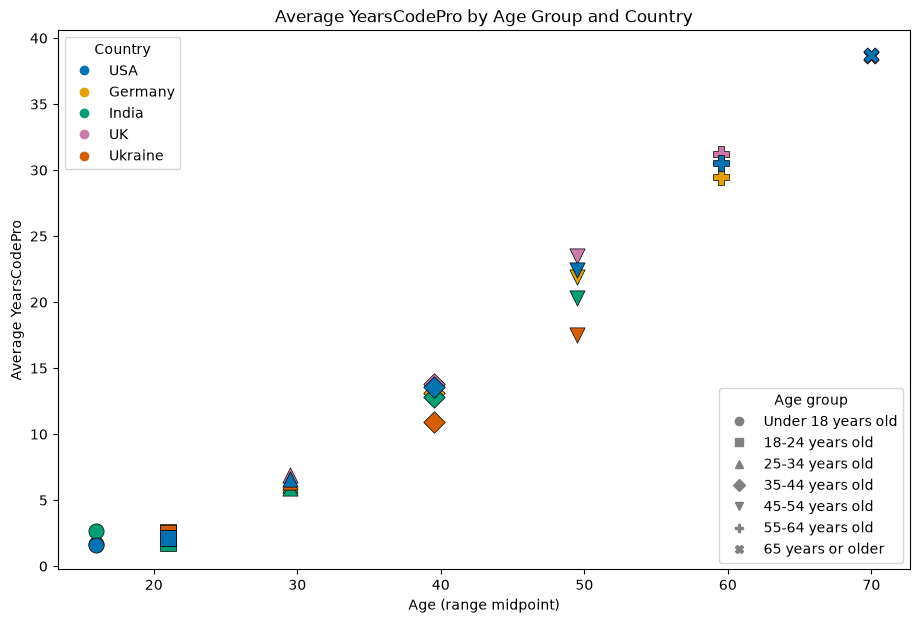

In [10]:
## Write your code here
d = df[["Country", "Age", "YearsCodePro"]].copy()
d["Age_numeric"] = d["Age"].map(age_map)
d["Years"] = pd.to_numeric(
    d["YearsCodePro"].replace({"Less than 1 year": 0.5, "More than 50 years": 50}), errors="coerce")
d = d.dropna()

top5 = df["Country"].value_counts().head(5).index.tolist()
short = {"United States of America": "USA", "United Kingdom of Great Britain and Northern Ireland": "UK"}
d = d[d["Country"].isin(top5)]

summary = (d.groupby(["Country", "Age"]).agg(avg_years=("Years", "mean"), n=("Years", "size"),
                                              age_mid=("Age_numeric", "first")).reset_index())
summary = summary[summary["n"] >= 20]
print(summary.round(1).sort_values(["Country", "age_mid"]).to_string(index=False))

age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]
age_markers = dict(zip(age_order, ["o", "s", "^", "D", "v", "P", "X"]))
colors = dict(zip(top5, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))

fig, ax = plt.subplots(figsize=(11, 7))
for _, r in summary.iterrows():
    ax.scatter(r["age_mid"], r["avg_years"], s=120, color=colors[r["Country"]],
               marker=age_markers[r["Age"]], edgecolor="black", linewidth=0.5)
ax.set_title("Average YearsCodePro by Age Group and Country")
ax.set_xlabel("Age (range midpoint)")
ax.set_ylabel("Average YearsCodePro")

from matplotlib.lines import Line2D
country_handles = [Line2D([0], [0], marker="o", linestyle="", color=colors[c], label=short.get(c, c)) for c in top5]
age_handles = [Line2D([0], [0], marker=age_markers[a], linestyle="", color="gray", label=a) for a in age_order]
leg1 = ax.legend(handles=country_handles, title="Country", loc="upper left")
ax.add_artist(leg1)
ax.legend(handles=age_handles, title="Age group", loc="lower right")
plt.show()

### Final Step: Review


With these scatter plots, you will have analyzed data relationships across multiple dimensions, including compensation, job satisfaction, employment types, and demographics, to uncover meaningful trends in the developer community.


### Summary


After completing this lab, you will be able to:
- Analyze how numerical variables relate across specific groups, such as employment types and countries.
- Use scatter plots effectively to represent multiple variables with color, size, and markers.
- Gain insights into compensation, satisfaction, and demographic trends using advanced scatter plot techniques.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
